# PCA

In [4]:
import os
import os.path as op
import os, sys, time
sys.path.append('.')

from paths import *
from tqdm.notebook import trange, tqdm
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn.image import iter_img, resample_to_img
from nilearn.plotting import plot_stat_map, show
from sklearn.decomposition import FastICA, PCA
from nilearn.masking import compute_epi_mask

from nilearn import datasets
from nilearn.input_data import NiftiMasker
from scipy.stats import zscore
from scipy.io import loadmat
from IPython.display import Image

save_results = 'results/'
if not os.path.exists(save_results):
    os.makedirs(save_results)
    
%matplotlib inline

## Load the data

In [5]:
img = nib.load(SMOOTH_PATH + ".nii.gz")
affine = img.affine
data = np.asanyarray(img.dataobj)                 # (x, y, z, time), float32
tr = float(img.header.get_zooms()[3])
print(data.shape, data.dtype, "| TR =", round(tr, 3), "s")

(91, 109, 91, 316) float32 | TR = 0.72 s


## Preprocessing

In [6]:
vol_shape = data.shape[:-1]
n_vols = data.shape[-1]
print("volume shape:", vol_shape, "| number of volumes:", n_vols)

volume shape: (91, 109, 91) | number of volumes: 316


In [7]:
mean_vol = data.mean(axis=3)
slice_non_background = compute_epi_mask(nib.Nifti1Image(mean_vol, affine)).get_fdata() > 0
print("brain voxels:", int(slice_non_background.sum()), "of", int(np.prod(vol_shape)))

# Vectorize: only brain voxels, one row per volume (the order matters: it is reversed in section 5)
samples = np.ascontiguousarray(data[slice_non_background].T)      # (n_vols, n_voxels)
del data, mean_vol                                                # free about 1 GB
print("samples:", samples.shape)

brain voxels: 207772 of 902629
samples: (316, 207772)


In [8]:
ZSCORE_VOXELS = False    # True: also give every voxel unit variance over time (weights all voxels equally)

spatial_means = samples.mean(axis=1)               # one value per volume, shape (n_vols,)
row_means = spatial_means[:, None]                 # broadcast over voxels (same as copying the means n_voxels times)
X = samples - row_means
del samples

if ZSCORE_VOXELS:
    sd = X.std(axis=0)
    sd[sd == 0] = 1
    X = (X - X.mean(axis=0)) / sd

# Check: the spatial mean of every volume is now ~0
print("max |mean over voxels| after subtraction:", float(np.abs(X.mean(axis=1)).max()))
print("X:", X.shape, X.dtype)

max |mean over voxels| after subtraction: 0.0013861347688362002
X: (316, 207772) float32


## Components exraction

In [9]:
nb_components = 60
t0 = time.time()
pca = PCA(n_components=nb_components, svd_solver="full")   # exact SVD
pca.fit(X)
print("PCA done in", round(time.time() - t0), "s")

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(ratios)

PCA done in 8 s


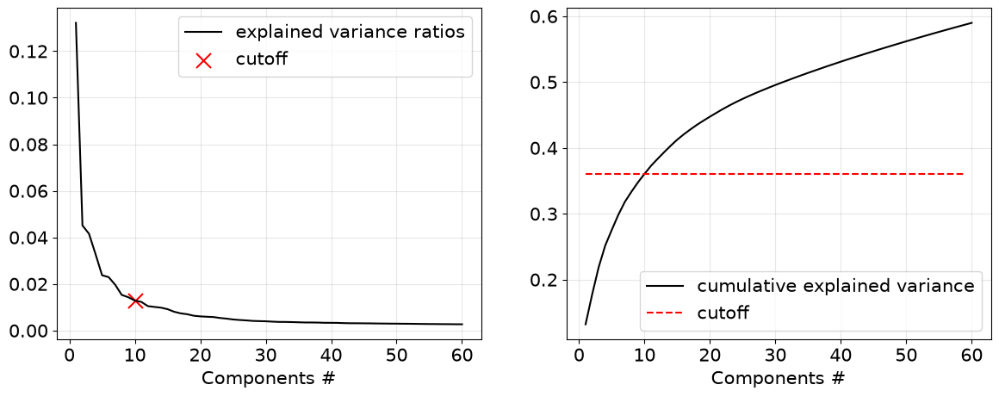

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(pca.explained_variance_ratio_)
nb_clusters = 10

ax[0].plot(np.arange(1, len(ratios)+1), ratios, label='explained variance ratios', c='k')
ax[0].scatter([nb_clusters], [ratios[nb_clusters-1]], [150], marker='x', color='r', label='cutoff')
ax[1].plot(np.arange(1, len(cumulative_ratios)+1), cumulative_ratios, label='cumulative explained variance', c='k')
ax[1].hlines(y=cumulative_ratios[nb_clusters-1], xmin=1, xmax=len(ratios)-1, linestyle='--', color='r', label='cutoff')

for k in range(2):
    ax[k].set_xlabel('Components #', size=15)
    ax[k].legend(prop={'size':15})
    ax[k].tick_params(axis='both', which='major', labelsize=15)

    ax[k].grid(True, alpha=0.3)

In [8]:
PCA_DIR = op.join(RESULTS_DIR, "PCA")        # loadings (NIfTI), scores and tables, for FSLeyes and the report
os.makedirs(PCA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## Back to original spatial domain

In [9]:
pca_clusters = []                                    # list of 3D volumes, one per kept component
for k in range(nb_components):
    vol = np.zeros(vol_shape, dtype=np.float32)
    vol[slice_non_background] = pca.components_[k]
    pca_clusters.append(vol)
    nib.save(nib.Nifti1Image(vol, affine), op.join(PCA_DIR, f"pca_loading_{k + 1:02d}.nii.gz"))   # for FSLeyes
print(len(pca_clusters), "loading maps saved in", PCA_DIR)

20 loading maps saved in /data/Desktop/myfiles/Project1_NSSP/results/PCA


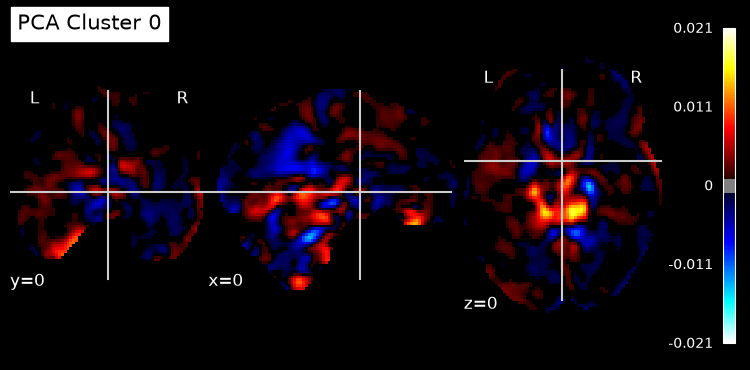

In [10]:
visual_idx = 0
plot_stat_map(nib.Nifti1Image(pca_clusters[visual_idx], affine), bg_img=None, threshold=1e-3,
               cut_coords=[0,0,0], black_bg=True, 
              title=f'PCA Cluster {visual_idx}')

plt.show()

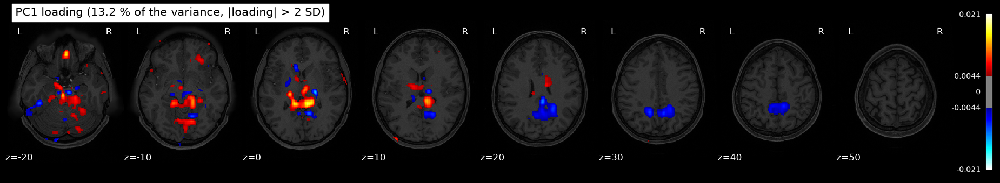

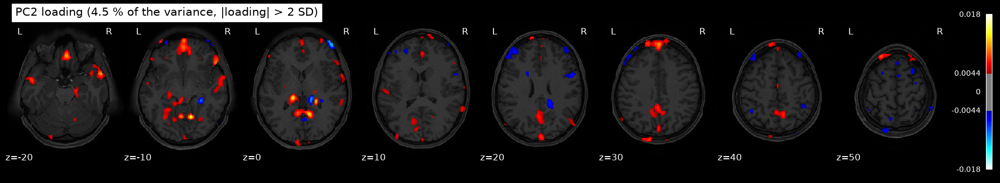

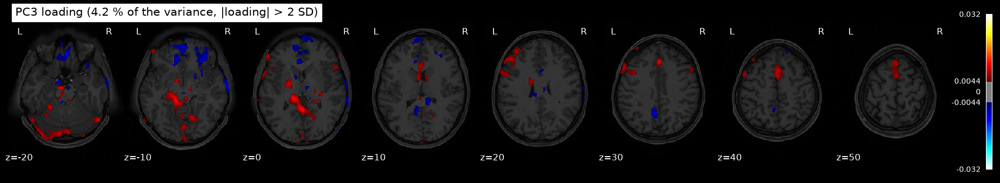

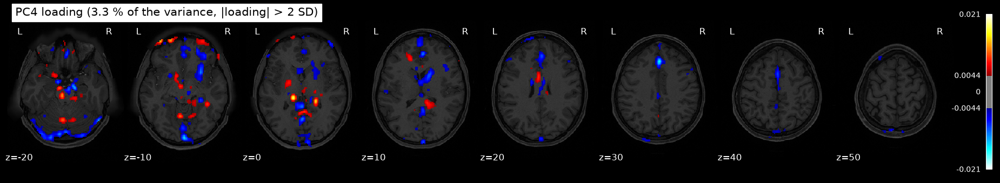

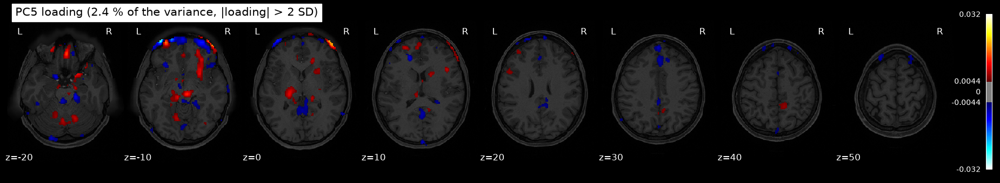

...

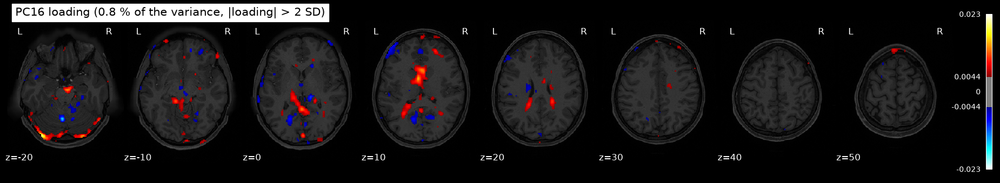

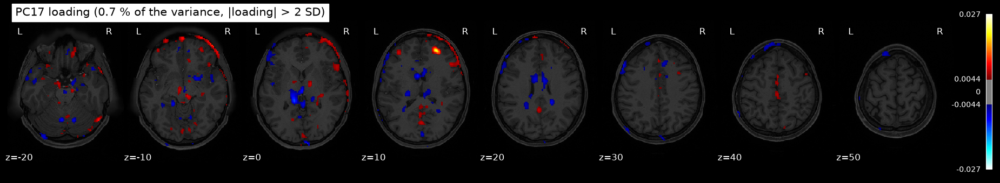

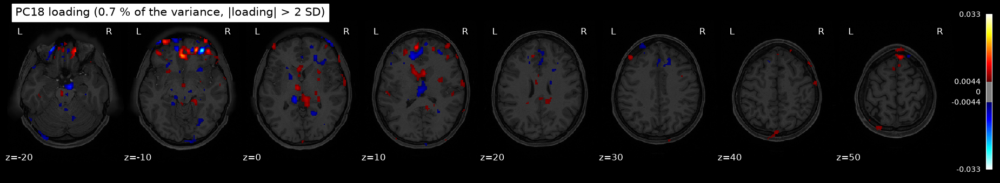

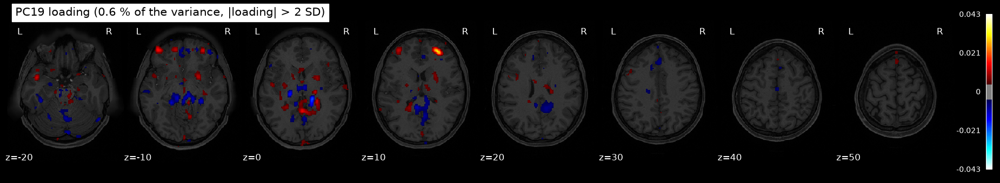

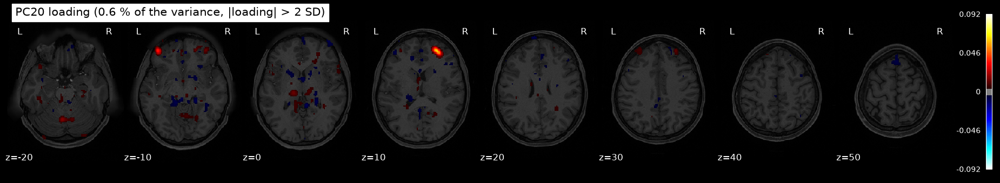

In [11]:
AXIAL_CUTS = (-20, -10, 0, 10, 20, 30, 40, 50)
for k, vol in enumerate(pca_clusters):
    thr = 2 * vol[slice_non_background].std()
    disp = plot_stat_map(nib.Nifti1Image(vol, affine), bg_img=ANAT_PATH, threshold=thr, display_mode="z",
                         cut_coords=AXIAL_CUTS, colorbar=True,
                         title=f"PC{k + 1} loading ({100 * ratios[k]:.1f} % of the variance, |loading| > 2 SD)")
    disp.savefig(op.join(FIG_DIR, f"PCA_loading_{k + 1:02d}.png"), dpi=150)
    plt.show()

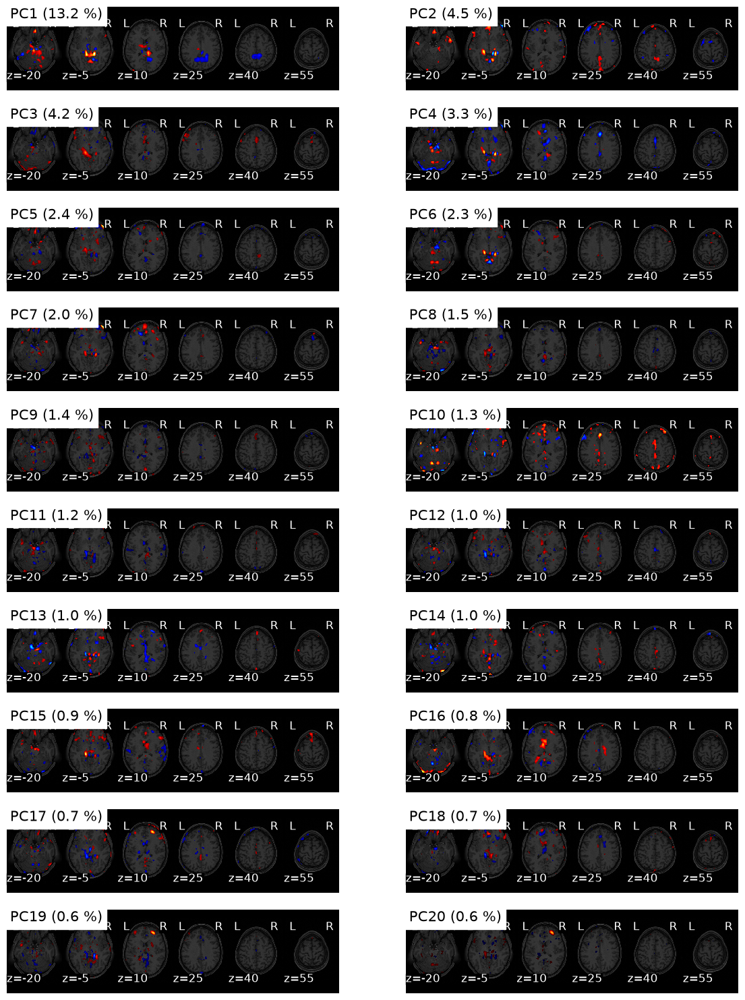

In [12]:
# Compact overview for the report: all kept loadings, axial slices only, two columns
ncols = 2
nrows = int(np.ceil(nb_components / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 1.9 * nrows))
for k, ax in enumerate(np.atleast_1d(axes).ravel()):
    if k >= nb_components:
        ax.axis("off")
        continue
    thr = 2 * pca_clusters[k][slice_non_background].std()
    plot_stat_map(nib.Nifti1Image(pca_clusters[k], affine), bg_img=ANAT_PATH, threshold=thr, display_mode="z",
                  cut_coords=(-20, -5, 10, 25, 40, 55), colorbar=False, axes=ax,
                  title=f"PC{k + 1} ({100 * ratios[k]:.1f} %)")
fig.savefig(op.join(FIG_DIR, "PCA_loadings_overview.png"), dpi=200, bbox_inches="tight")
plt.show()

In [13]:
dm_path = op.join(RESULTS_DIR, "design_matrix.csv")
op.exists(dm_path)
design_matrix = pd.read_csv(dm_path, index_col=0)
print("design matrix read from", dm_path)

reg = design_matrix.drop(columns=["constant"])
reg["story - math"] = reg["story"] - reg["math"]
first = ["story", "math", "story - math"]
reg = reg[first + [c for c in reg.columns if c not in first]]
print("regressors:", reg.columns.tolist())

design matrix read from /data/Desktop/myfiles/Project1_NSSP/results/design_matrix.csv
regressors: ['story', 'math', 'story - math', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4']


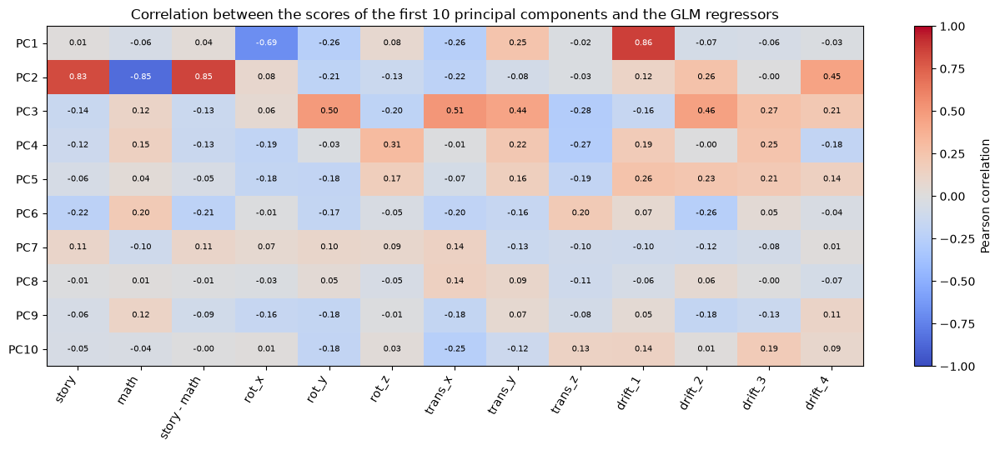

In [17]:
scores = pca.transform(X)                              # (n_vols, nb_max): temporal scores
n_corr = 10
score_df = pd.DataFrame(scores[:, :n_corr], columns=[f"PC{i + 1}" for i in range(n_corr)])
pd.DataFrame(scores[:, :nb_components], columns=[f"PC{i + 1}" for i in range(nb_components)]).to_csv(op.join(PCA_DIR, "pca_scores.csv"), index=False)

S = scores[:, :n_corr]
R = reg.to_numpy(dtype=float)
corr = pd.DataFrame(
    [[np.corrcoef(S[:, i], R[:, j])[0, 1] for j in range(R.shape[1])] for i in range(n_corr)],
    index=score_df.columns, columns=reg.columns)
corr.round(3).to_csv(op.join(PCA_DIR, "pca_vs_glm_correlation.csv"))

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(corr.shape[1])); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(corr.shape[0])); ax.set_yticklabels(corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between the scores of the first 10 principal components and the GLM regressors")
plt.tight_layout()
fig.savefig(op.join(FIG_DIR, "PCA_correlation_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

In [16]:
print("NaN dans les scores :", int(np.isnan(scores).sum()))
print("NaN dans X :", int(np.isnan(X).sum()))
print("NaN par régresseur :", reg.isna().sum()[reg.isna().sum() > 0].to_dict())
print("index scores :", score_df.index[:3].tolist(), "| index reg :", reg.index[:3].tolist(), "| tailles :", len(score_df), len(reg))

NaN dans les scores : 0
NaN dans X : 0
NaN par régresseur : {}
index scores : [0, 1, 2] | index reg : [0.0, 0.7200000286102295, 1.440000057220459] | tailles : 316 316
